# Libraries

In [535]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.preprocessing import OneHotEncoder
from sklearn.preprocessing import OrdinalEncoder

from imblearn.over_sampling import SMOTE

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

In [536]:
file_path = "/content/drive/MyDrive/ICT_AIML_DATAS/DataFrame/Customer.csv"

# EDA

In [537]:
df = pd.read_csv(file_path)

In [538]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [539]:
df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [540]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [541]:
df.shape

(7043, 21)

In [542]:
df.value_counts().sum()

np.int64(7043)

In [543]:
df.duplicated().sum()

np.int64(0)

In [544]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [545]:
df["Churn"].value_counts()

,count
Churn,
No,5174
Yes,1869


# Data Visualization

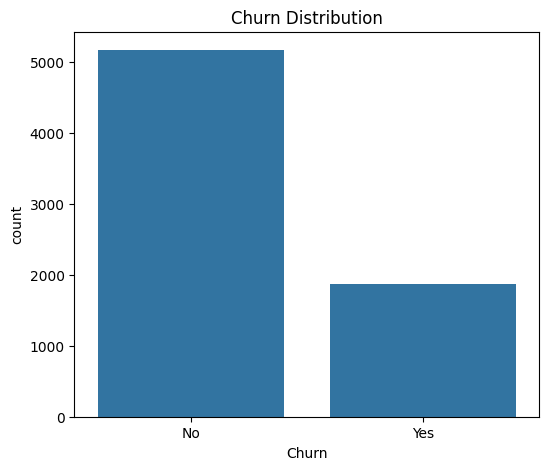

In [546]:
# Target distribution plot for checking class imbalance visually

plt.figure(figsize=(6, 5))
sns.countplot(df, x="Churn")
plt.title("Churn Distribution")
plt.show()

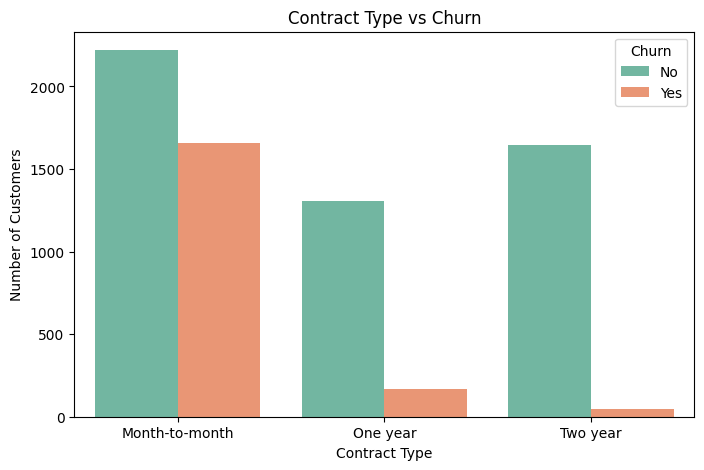

In [547]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='Contract', hue='Churn', palette='Set2')
plt.title("Contract Type vs Churn")
plt.xlabel("Contract Type")
plt.ylabel("Number of Customers")
plt.show()

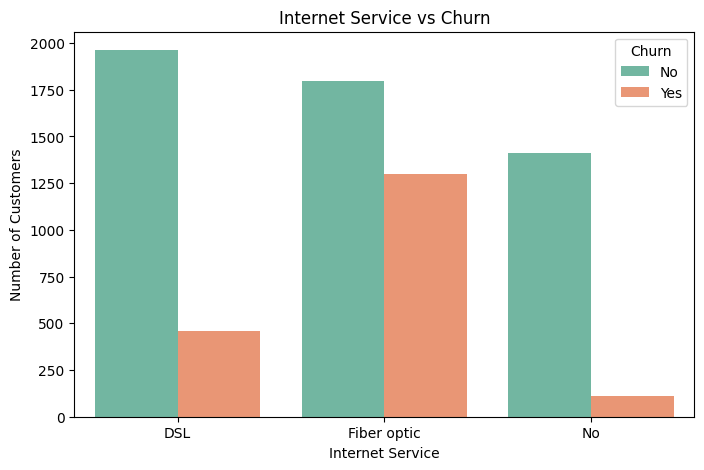

In [548]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x='InternetService', hue='Churn', palette='Set2')
plt.title("Internet Service vs Churn")
plt.xlabel("Internet Service")
plt.ylabel("Number of Customers")
plt.show()

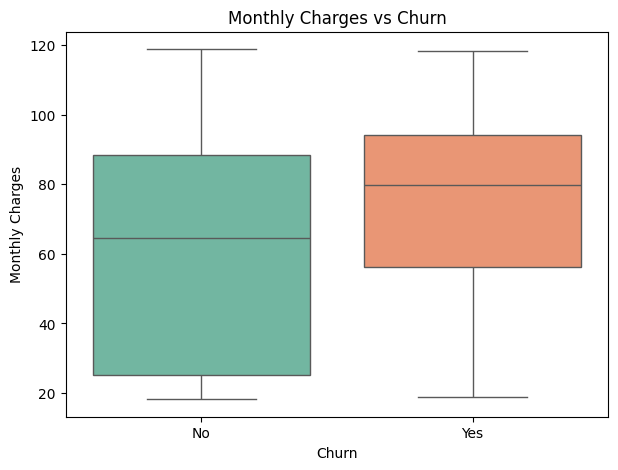

In [549]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Churn', y='MonthlyCharges', hue='Churn', palette='Set2', legend=False)
plt.title("Monthly Charges vs Churn")
plt.xlabel("Churn")
plt.ylabel("Monthly Charges")
plt.show()

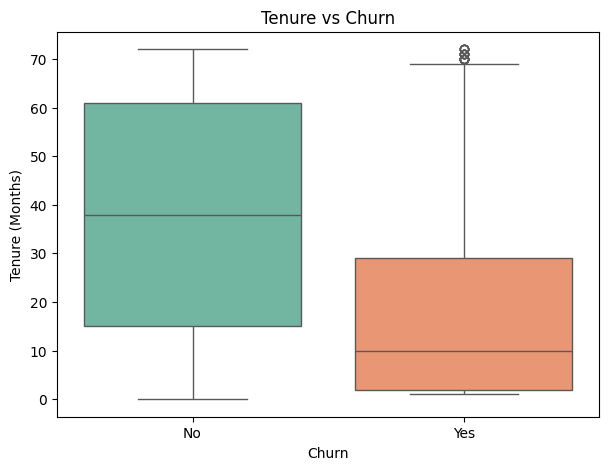

In [550]:
plt.figure(figsize=(7,5))
sns.boxplot(data=df, x='Churn', y='tenure', hue='Churn', palette='Set2', legend=False)
plt.title("Tenure vs Churn")
plt.xlabel("Churn")
plt.ylabel("Tenure (Months)")
plt.show()

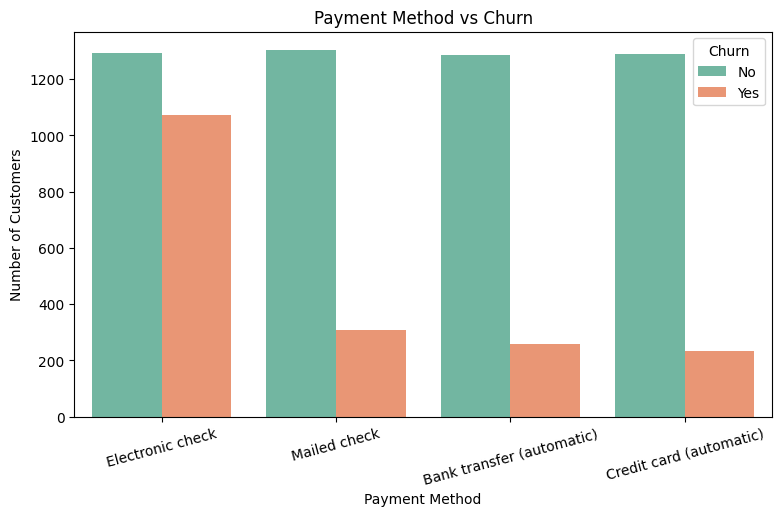

In [551]:
plt.figure(figsize=(9,5))
sns.countplot(data=df, x='PaymentMethod', hue='Churn', palette='Set2')
plt.title("Payment Method vs Churn")
plt.xlabel("Payment Method")
plt.ylabel("Number of Customers")
plt.xticks(rotation=15)
plt.show()

# Data Cleaning

In [552]:
df = df.drop(columns = "customerID")

In [553]:
print(df['TotalCharges'].unique())
print(df['TotalCharges'].dtype)

['29.85' '1889.5' '108.15' ... '346.45' '306.6' '6844.5']
object


In [554]:
# TotalCharges is stored as object because some values contain blank spaces.
df['TotalCharges'].str.strip().eq('').sum()
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'].str.strip(), errors='coerce')

In [555]:
print(df['TotalCharges'].dtype)

float64


In [556]:
df.isnull().sum()/ len(df)*100

,0
gender,0.000000
SeniorCitizen,0.000000
Partner,0.000000
Dependents,0.000000
tenure,0.000000
PhoneService,0.000000
MultipleLines,0.000000
InternetService,0.000000
OnlineSecurity,0.000000
OnlineBackup,0.000000


In [557]:
df.dropna(subset=['TotalCharges'], inplace=True)

In [558]:
df.isnull().sum()

,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0
OnlineBackup,0


In [559]:
cat_cols_before_split = df.select_dtypes(exclude="number")

for col in cat_cols_before_split:
  print(f"{col} ---> {df[col].unique()}")
  print(" ")

gender ---> ['Female' 'Male']
 
Partner ---> ['Yes' 'No']
 
Dependents ---> ['No' 'Yes']
 
PhoneService ---> ['No' 'Yes']
 
MultipleLines ---> ['No phone service' 'No' 'Yes']
 
InternetService ---> ['DSL' 'Fiber optic' 'No']
 
OnlineSecurity ---> ['No' 'Yes' 'No internet service']
 
OnlineBackup ---> ['Yes' 'No' 'No internet service']
 
DeviceProtection ---> ['No' 'Yes' 'No internet service']
 
TechSupport ---> ['No' 'Yes' 'No internet service']
 
StreamingTV ---> ['No' 'Yes' 'No internet service']
 
StreamingMovies ---> ['No' 'Yes' 'No internet service']
 
Contract ---> ['Month-to-month' 'One year' 'Two year']
 
PaperlessBilling ---> ['Yes' 'No']
 
PaymentMethod ---> ['Electronic check' 'Mailed check' 'Bank transfer (automatic)'
 'Credit card (automatic)']
 
Churn ---> ['No' 'Yes']
 


In [560]:
X = df.drop(columns="Churn")
y = df["Churn"]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

In [561]:
num_cols = X_train.select_dtypes(include="number").columns
cat_cols = X_train.select_dtypes(exclude="number").columns

# Scaling

In [562]:
scaler = StandardScaler()

# Scale the actual numeric data from X_train and X_test using the num_cols index
X_train_num_scaled = scaler.fit_transform(X_train[num_cols])
X_test_num_scaled = scaler.transform(X_test[num_cols])

In [563]:
X_train_num_scaled = pd.DataFrame(X_train_num_scaled, columns=num_cols, index=X_train.index)
X_test_num_scaled = pd.DataFrame(X_test_num_scaled, columns=num_cols, index=X_test.index)


X_train_cat = pd.DataFrame(X_train[cat_cols], columns=cat_cols, index=X_train.index)
X_test_cat = pd.DataFrame(X_test[cat_cols], columns=cat_cols, index=X_test.index)

# Encoding

In [564]:
for col in cat_cols:
  print(f"{col} ---->  {X_train_cat[col].unique()}")
  print(" ")

gender ---->  ['Male' 'Female']
 
Partner ---->  ['Yes' 'No']
 
Dependents ---->  ['Yes' 'No']
 
PhoneService ---->  ['Yes' 'No']
 
MultipleLines ---->  ['Yes' 'No phone service' 'No']
 
InternetService ---->  ['Fiber optic' 'DSL' 'No']
 
OnlineSecurity ---->  ['Yes' 'No' 'No internet service']
 
OnlineBackup ---->  ['Yes' 'No' 'No internet service']
 
DeviceProtection ---->  ['Yes' 'No' 'No internet service']
 
TechSupport ---->  ['Yes' 'No' 'No internet service']
 
StreamingTV ---->  ['No' 'Yes' 'No internet service']
 
StreamingMovies ---->  ['No' 'Yes' 'No internet service']
 
Contract ---->  ['Two year' 'Month-to-month' 'One year']
 
PaperlessBilling ---->  ['No' 'Yes']
 
PaymentMethod ---->  ['Credit card (automatic)' 'Electronic check' 'Bank transfer (automatic)'
 'Mailed check']
 


In [565]:
ord_enc = OrdinalEncoder(
    categories=[['Month-to-month', 'One year', 'Two year']]
)

ord_train = pd.DataFrame(
    ord_enc.fit_transform(X_train_cat[['Contract']]),
    columns=['Contract'],
    index=X_train.index
)

ord_test = pd.DataFrame(
    ord_enc.transform(X_test_cat[['Contract']]),
    columns=['Contract'],
    index=X_test.index
)

In [566]:
oh_cols = [
    "gender", "Partner", "Dependents", "PhoneService",
    "MultipleLines", "InternetService", "OnlineSecurity",
    "OnlineBackup", "DeviceProtection", "TechSupport",
    "StreamingTV", "StreamingMovies", "PaperlessBilling",
    "PaymentMethod"
]

oh_enc = OneHotEncoder(handle_unknown="ignore", sparse_output=False)

oh_train = pd.DataFrame(
    oh_enc.fit_transform(X_train_cat[oh_cols]),
    columns=oh_enc.get_feature_names_out(oh_cols),
    index=X_train.index
)

oh_test = pd.DataFrame(
    oh_enc.transform(X_test_cat[oh_cols]),
    columns=oh_enc.get_feature_names_out(oh_cols),
    index=X_test.index
)

In [567]:
X_train_final = pd.concat([X_train_num_scaled, ord_train, oh_train], axis=1)
X_test_final = pd.concat([X_test_num_scaled, ord_test, oh_test], axis=1)

print(X_train_final.shape, X_test_final.shape)
X_train_final.head()


(5625, 43) (1407, 43)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,Contract,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,...,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
1413,-0.439319,1.321816,0.981556,1.659900,2.0,0.0,1.0,0.0,1.0,0.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
7003,-0.439319,-0.267410,-0.971546,-0.562252,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
3355,-0.439319,1.444064,0.837066,1.756104,2.0,1.0,0.0,0.0,1.0,1.0,...,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0
4494,-0.439319,-1.204646,0.641092,-0.908326,0.0,0.0,1.0,1.0,0.0,1.0,...,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0
3541,-0.439319,0.669826,-0.808787,-0.101561,0.0,1.0,0.0,0.0,1.0,1.0,...,1.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0


In [568]:
print(X_train_final.isnull().sum().sum())
print(X_test_final.isnull().sum().sum())

0
0


In [569]:
y_train = y_train.map({'No': 0, 'Yes': 1})
y_test = y_test.map({'No': 0, 'Yes': 1})

In [570]:
print(y_test.value_counts())
print(y_test.isnull().sum())

Churn
0    1033
1     374
Name: count, dtype: int64
0


# Class Imbalance

In [571]:
smote = SMOTE(random_state=42)

X_train_smote, y_train_smote = smote.fit_resample(X_train_final, y_train)

print(y_train_smote.value_counts())

Churn
0    4130
1    4130
Name: count, dtype: int64


# Feature Selection

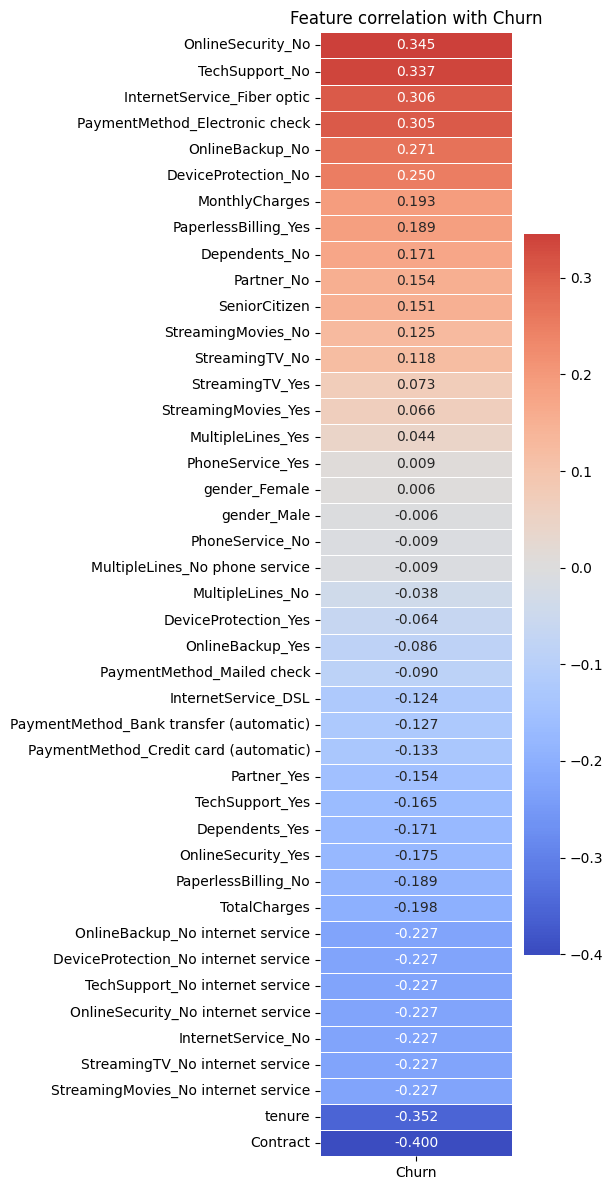

In [572]:
corr = X_train_final.corrwith(y_train).sort_values(ascending=False).to_frame("Churn")

plt.figure(figsize=(6, 12))
sns.heatmap(
    corr,
    annot=True,
    cmap="coolwarm",
    fmt=".3f",
    linewidths=0.5,
    center=0
)
plt.title("Feature correlation with Churn")
plt.tight_layout()
plt.show()

In [573]:
features_selected = ['Contract', 'tenure','OnlineBackup_No']
X_train_selected = X_train_smote[features_selected]
X_test_selected = X_test_final[features_selected]

# Logistic Regression

In [574]:
log_reg = LogisticRegression()
knn = KNeighborsClassifier(n_neighbors = 3)

In [575]:
log_reg.fit(X_train_selected, y_train_smote)
knn.fit(X_train_selected, y_train_smote)

KNeighborsClassifier(n_neighbors=3)

In [576]:
#Predict the target labels for the training set using the trained Logistic Regression model
lr_train_pred = log_reg.predict(X_train_selected)
# Predict the target labels for the test set using the trained Logistic Regression model
lr_test_pred = log_reg.predict(X_test_selected)

In [577]:
#Predict the target labels for the training set using the trained (KNN)
knn_train_pred = knn.predict(X_train_selected)
# Predict the target labels for the test set using the trained (KNN)
knn_test_pred = knn.predict(X_test_selected)

# Accuracy Score

In [578]:
#Accuracy Score
# Calculate accuracy on train set
lr_train_acc = accuracy_score(y_train_smote, lr_train_pred)

# Calculate accuracy on test set
lr_test_acc = accuracy_score(y_test, lr_test_pred)

In [579]:
# Print the training accuracy of the logistic Regression model
print(f" Logistic Regression Train Accuracy : {lr_train_acc:.4f}")

# Print the testing accuracy of the Logistic Regression Model
print(f" Logistic Regression Test Accuracy : {lr_test_acc:.4f}")

 Logistic Regression Train Accuracy : 0.7378
 Logistic Regression Test Accuracy : 0.6667


# KNN

In [580]:
#KNN Score
# Calculate KNN on train set
knn_train_acc = accuracy_score(y_train_smote, knn_train_pred)

# Calculate KNN on test set
knn_test_acc = accuracy_score(y_test, knn_test_pred)

In [581]:
# Print the training accuracy of KNN
print(f" KNN Train Accuracy : {knn_train_acc:.4f}")

# Print the testing accuracy of KNN
print(f" KNN Test Accuracy : {knn_test_acc:.4f}")

 KNN Train Accuracy : 0.7952
 KNN Test Accuracy : 0.7321


# Confusion Matrix

In [582]:
# Calculate the confusion matrix for the Logistic Regression model on the test set
lr_cm = confusion_matrix(y_test, lr_test_pred)

#Print the confusion matrix to visualize model performance
print("Confusion Matrix: ")
print(lr_cm)


Confusion Matrix: 
[[622 411]
 [ 58 316]]


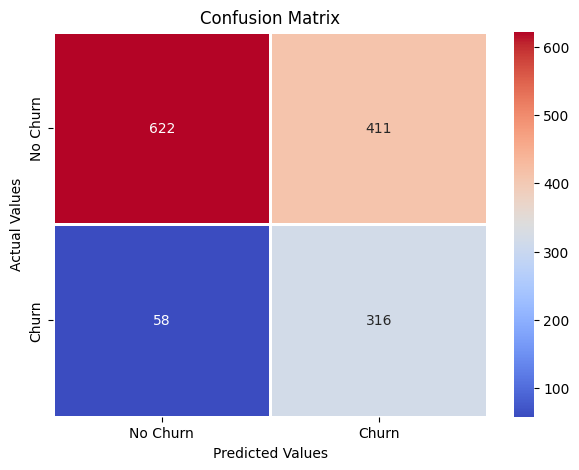

In [583]:
#HEAT MAP
plt.figure(figsize=(7,5))
sns.heatmap(
    lr_cm,
    annot=True,
    fmt='d',
    cmap='coolwarm',
    linewidths=1,
    xticklabels=['No Churn', 'Churn'],
    yticklabels=['No Churn', 'Churn']
)
plt.title("Confusion Matrix")
plt.xlabel("Predicted Values")
plt.ylabel("Actual Values")
plt.show()

# Classification Report

In [584]:
#Generates a classification report for the Logistic Regression model on the test set

log_cr = classification_report(y_test, lr_test_pred)

#Print the classification report to evaluate model performance in detail
print("Classification Report:")
print(log_cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.91      0.60      0.73      1033
           1       0.43      0.84      0.57       374

    accuracy                           0.67      1407
   macro avg       0.67      0.72      0.65      1407
weighted avg       0.79      0.67      0.69      1407



In [585]:
#Generates a classification report for the KNN on the test set
KNN_cr = classification_report(y_test, knn_test_pred)
print("Classification Report:")
print(KNN_cr)

Classification Report:
              precision    recall  f1-score   support

           0       0.80      0.84      0.82      1033
           1       0.50      0.43      0.46       374

    accuracy                           0.73      1407
   macro avg       0.65      0.63      0.64      1407
weighted avg       0.72      0.73      0.73      1407

